# Single z-invariant layer: tunable complex PB phase (v4)

**Goal.** One patterned, z-invariant, passive layer whose meta-atom has a physical parameter $u$ that controls the
*imaginary* part of the rotation-cycle (PB) geometric phase while leaving its real, path-dependent part nearly fixed.
This is the element needed to test whether the complex geometric phase of Jana & Genevet ("Complex Geometric Phase from
Nonorthogonal Polarization Transport") survives lateral arrangement or needs ordered (multilayer) transport.

**Figure of merit.** Write the transmission Jones matrix as $T=t_0I+\mathbf t\cdot\boldsymbol\sigma$ (lab linear basis) and
$\hat k=\mathbf t/\sqrt{\mathbf t\cdot\mathbf t}$. Rigidly rotating the meta-atom, $\theta:0\to\pi$, gives the biorthogonal
Wilson-loop phases $\gamma_\pm=\pi(1\mp\hat k_y)$ (checked against discrete Wilson loops in `tests/test_theta_loop.py`).
$\hat k_y$ is the circular component, i.e. the axis of physical rotation. The paper's model, realized by rotation, is
$K'=\sigma_z+i\eta\sigma_y$ and gives $\gamma_\pm=\pi\pm i\pi\eta/\sqrt{1-\eta^2}$.

**Symmetry constraint.** A reciprocal layer with z-mirror symmetry has $T=T^\mathsf T$, so $\hat k_y=0$ and $\gamma=\pi$ for
*any* eigenvector overlap. The v3 TiO₂ two-fin in silica is such a negative control. A z-invariant layer can break the mirror only
through unequal claddings, so here the fins sit on SiO₂ with **air above**. Loss (complex index) supplies passive non-Hermiticity.

**Objective.** Maximize the span of $\operatorname{Im}\gamma$ over $u\in[-1,1]$ (span of $\pi\,\mathrm{Im}\,\hat k_y$) while penalizing
(i) variation of $\operatorname{Re}\gamma$ (the path-dependent PB phase), (ii) **locality violation**: $\hat k_y$ is exactly
rotation-invariant for a local meta-atom, so its change when the atom is rotated inside the square lattice measures lattice
(nonlocal) contributions, and (iii) transmission below a floor. The $u$ samples are jittered every step, so a narrow
resonance cannot sit on a training point (the v3 failure mode). Selection uses a dense, fixed grid at a higher order.

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
import json, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from scipy.stats import qmc
from scipy.special import logit

from engine_twofin_eta import (
    Physics, RCWA, Modulation, PARAM_KEYS, BOUNDS, device_dtype, design_from_raw, raw_from_physical, vary,
    twofin_mask, check_connected, geometry_penalty, solve_torch, jones_metrics, numpy_metrics,
    pauli_khat, theta_loop_phase, transpose_asymmetry, virtual_wilson, export_layout, diffraction_audit)

OUT = Path('results/complex_pb_v4'); OUT.mkdir(parents=True, exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
# c-Si fins on SiO2, air above (approximate 633 nm optical constants; replace with measured n, k).
PHYS = Physics(n_fin=3.88, k_fin=0.019, n_background=1.0, n_bottom=1.46, n_top=1.0, height=0.495)
MOD = Modulation(parameter='junction_frac', amplitude=0.10)   # smooth planar-chirality knob (see sensitivity screen)
# NV factorization + area-fraction mask are engine defaults; NV requires complex128.
SCREEN = RCWA(order=8, raster=160, device=DEVICE, precision='complex128')
COARSE = SCREEN
REFINE = RCWA(order=10, raster=192, device=DEVICE, precision='complex128')
ACCEPT = RCWA(order=12, raster=256, device=DEVICE, precision='complex128')
VERIFY_ORDERS = (8, 10, 12, 14, 16)
THETA_LOC = 22.5                       # rotation used for the in-training locality penalty (deg)
ACCEPT_THETAS = (0.0, 22.5, 45.0)
TRAIN_BINS = 5; ACCEPT_U = np.linspace(-1, 1, 7)
SEED = 67; N_SCREEN = 64; N_KEEP = 3; COARSE_STEPS = 50; REFINE_STEPS = 20; N_RESCORE = 2
W_RE, W_LOC, W_P, FAB_WEIGHT = 1.0, 2.0, 4.0, 0.40
P_FLOOR = 0.30        # transmitted power floor in the loss
MIN_P_ACCEPT, MIN_GAP_ACCEPT, MAX_LOC_ACCEPT = 0.25, 0.05, 0.15   # ACCEPT: P, eigen-gap, locality RMS (rad)
RUN_SCREEN = RUN_OPTIMIZE = RUN_VERIFY = True
print('Device:', DEVICE, '| u =', MOD, '\n', asdict(PHYS))
for region, d in diffraction_audit(PHYS).items():
    if isinstance(d, dict): print(f'{region:14} n={d["index"]:.3f} first order propagating={d["first_order_propagating"]}')

Device: cuda | u = Modulation(parameter='junction_frac', amplitude=0.1) 
 {'wavelength': 0.633, 'period': 0.4, 'n_fin': 3.88, 'k_fin': 0.019, 'n_background': 1.0, 'n_bottom': 1.46, 'n_top': 1.0, 'height': 0.495, 'cell_margin': 0.012}
bottom         n=1.460 first order propagating=False
top            n=1.000 first order propagating=False
background     n=1.000 first order propagating=False
fin_reference  n=3.880 first order propagating=True


## Objective
`u` samples: one jittered point per bin of $[-1,1]$ (training) or the fixed `ACCEPT_U` grid (selection). Forward illumination is
from the substrate (port 1) into air (port 2); reversing it transposes $T$ and flips the sign of $\hat k_y$.

In [2]:
def jitter_u(rng):
    edges = np.linspace(-1, 1, TRAIN_BINS + 1)
    return np.sort(rng.uniform(edges[:-1], edges[1:]))

def evaluate(raw, opts, us, thetas=(0.0, THETA_LOC)):
    p = design_from_raw(raw)
    ky = {t: [] for t in thetas}; jm = []
    for u in us:
        q = vary(p, MOD, float(u))
        for t in thetas:
            T = solve_torch(q, PHYS, opts, theta_deg=t)[2:4, :2]
            ky[t].append(pauli_khat(T)[1])
            if t == thetas[0]: jm.append(jones_metrics(T))
    k0 = torch.stack(ky[thetas[0]])
    im, re = k0.imag, k0.real
    span = im.max() - im.min()
    re_ms = ((re - re.mean())**2).mean()
    loc_ms = torch.stack([(torch.stack(ky[t]) - k0).abs().square().mean() for t in thetas[1:]]).mean()
    power = torch.stack([m['power'] for m in jm])
    fab = torch.stack([geometry_penalty(vary(p, MOD, float(u)), PHYS)[0] for u in us]).mean()
    loss = (-np.pi*span + W_RE*np.pi**2*re_ms + W_LOC*np.pi**2*loc_ms
            + W_P*torch.relu(P_FLOOR - power).square().sum() + FAB_WEIGHT*fab)
    lo, hi = BOUNDS[MOD.parameter]
    in_bounds = all(bool((vary(p, MOD, float(u))[MOD.parameter] >= lo) & (vary(p, MOD, float(u))[MOD.parameter] <= hi)) for u in us)
    eta = torch.stack([m['eta'] for m in jm]); gap = torch.stack([m['gap'] for m in jm])
    valid = torch.stack([m['eta_defined'] for m in jm]).all() & torch.tensor(in_bounds)
    d = dict(imgamma_span=np.pi*span, re_rms=np.pi*torch.sqrt(re_ms), loc_rms=np.pi*torch.sqrt(loc_ms),
             P_min=power.min(), eta_min=eta.min(), eta_max=eta.max(), gap_min=gap.min(), valid=valid,
             im_ky_mid=im[len(im)//2], re_ky_mid=re[len(re)//2])
    return loss, d

def scalars(d):
    return {k: float(v.detach().cpu()) if isinstance(v, torch.Tensor) else float(v) for k, v in d.items()}

def reference_score(raw):
    with torch.no_grad():
        r = torch.as_tensor(np.asarray(raw), device=DEVICE, dtype=device_dtype(ACCEPT))
        loss, d = evaluate(r, ACCEPT, ACCEPT_U, ACCEPT_THETAS)
    out = dict(loss=float(loss.cpu()), **scalars(d))
    out['accepted'] = (bool(out['valid']) and out['P_min'] >= MIN_P_ACCEPT and out['gap_min'] >= MIN_GAP_ACCEPT
                       and out['loc_rms'] <= MAX_LOC_ACCEPT)
    return out

def fmt(d):
    return (f"Im γ span={d['imgamma_span']:.3f} rad, Re γ rms={d['re_rms']:.3f}, locality rms={d['loc_rms']:.3f}, "
            f"P≥{d['P_min']:.2f}, η∈[{d['eta_min']:.2f},{d['eta_max']:.2f}], gap≥{d['gap_min']:.2f}")

## Screen, optimize, re-score at `ACCEPT`

In [3]:
sobol = qmc.Sobol(d=len(PARAM_KEYS), scramble=True, seed=SEED)
seeds = logit(np.clip(sobol.random_base2(int(np.ceil(np.log2(N_SCREEN))))[:N_SCREEN], .08, .92))
# Best random c-Si sample from the family screen (k_y = -0.113-0.105i, rotation-stable), as a warm start.
seed8 = {'length1': 0.1711, 'width1': 0.075, 'length2': 0.1987, 'width2': 0.0632, 'bend_deg': 76.1527, 'junction_frac': 0.0079}
seeds = np.vstack((raw_from_physical(seed8)[None, :], seeds))[:N_SCREEN]
fixed_u = np.linspace(-1, 1, TRAIN_BINS)
start_list = []
if RUN_SCREEN:
    t0 = time.perf_counter()
    for k, raw in enumerate(seeds):
        try:
            with torch.no_grad():
                loss, d = evaluate(torch.tensor(raw, device=DEVICE, dtype=device_dtype(SCREEN)), SCREEN, fixed_u)
            row = dict(index=k, loss=float(loss.cpu()), raw=np.asarray(raw), **scalars(d))
            if np.isfinite(row['loss']) and row['valid']: start_list.append(row)
        except (RuntimeError, ValueError) as err:
            print(f'Screen skip {k}: {str(err)[:140]}')
        if (k+1) % 8 == 0: print(f'Screen {k+1}/{N_SCREEN} | valid {len(start_list)}', flush=True)
    start_list.sort(key=lambda r: r['loss'])
    print('Screen seconds:', round(time.perf_counter()-t0, 1))
    for r in start_list[:6]: print(f"score {r['loss']:+.3f} | {fmt(r)}")

Screen 8/64 | valid 5


Screen 16/64 | valid 11


Screen 24/64 | valid 14


Screen 32/64 | valid 19


Screen 40/64 | valid 22


Screen 48/64 | valid 27


Screen 56/64 | valid 31


Screen 64/64 | valid 36


Screen seconds: 584.5
score -0.645 | Im γ span=0.707 rad, Re γ rms=0.165, locality rms=0.132, P≥0.49, η∈[0.08,0.31], gap≥0.07
score -0.504 | Im γ span=1.262 rad, Re γ rms=0.262, locality rms=0.332, P≥0.07, η∈[0.23,0.47], gap≥1.03
score -0.154 | Im γ span=0.164 rad, Re γ rms=0.067, locality rms=0.051, P≥0.30, η∈[0.14,0.30], gap≥0.18
score -0.122 | Im γ span=0.163 rad, Re γ rms=0.058, locality rms=0.062, P≥0.24, η∈[0.03,0.09], gap≥0.31
score -0.106 | Im γ span=0.112 rad, Re γ rms=0.043, locality rms=0.042, P≥0.29, η∈[0.02,0.07], gap≥0.86
score -0.089 | Im γ span=0.121 rad, Re γ rms=0.069, locality rms=0.116, P≥0.32, η∈[0.10,0.22], gap≥0.98


In [4]:
def adam_run(raw0, opts, steps, lr, label, rng):
    raw = torch.nn.Parameter(torch.tensor(raw0, device=DEVICE, dtype=device_dtype(opts)))
    opt = torch.optim.Adam([raw], lr=lr); history = []
    for it in range(steps):
        opt.zero_grad(set_to_none=True)
        try:
            loss, d = evaluate(raw, opts, jitter_u(rng))
            if not bool(torch.isfinite(loss)): break
            loss.backward()
            if raw.grad is None or not bool(torch.isfinite(raw.grad).all()): break
            torch.nn.utils.clip_grad_norm_([raw], 1.)
            rec = dict(iteration=it, loss=float(loss.detach().cpu()), raw=raw.detach().cpu().numpy().tolist(), **scalars(d))
            history.append(rec); opt.step()
            if it == 0 or (it+1) % 10 == 0: print(f"{label} {it+1:3}/{steps}: loss={rec['loss']:+.3f} | {fmt(rec)}", flush=True)
        except (RuntimeError, ValueError) as exc:
            print(f'{label}: terminated at iteration {it}: {exc}'); break
    return history

def rescore(stage, history, k=N_RESCORE):
    pool = sorted([h for h in history if h['valid']], key=lambda h: h['loss'])[:k]
    if history and all(h['iteration'] != history[-1]['iteration'] for h in pool): pool.append(history[-1])
    out = []
    for h in pool:
        ref = reference_score(h['raw'])
        out.append(dict(stage=stage, iteration=h['iteration'], train_loss=h['loss'], raw=h['raw'], ref=ref))
        print(f"   ACCEPT {stage} it {h['iteration']:3}: {fmt(ref)} | accepted={ref['accepted']}", flush=True)
    return out

checkpoint = OUT/'complex_pb_checkpoint_v4.npz'
trajectories, rescored, best_raw = [], [], None
if RUN_OPTIMIZE and start_list:
    rng = np.random.default_rng(SEED + 1)
    for i, entry in enumerate(start_list[:N_KEEP]):
        print(f'\n>>> Candidate {i+1}/{N_KEEP}')
        c = adam_run(entry['raw'], COARSE, COARSE_STEPS, .03, f'C{i} coarse', rng)
        best_c = min([h for h in c if h['valid']] or c, key=lambda h: h['loss'])
        r = adam_run(best_c['raw'], REFINE, REFINE_STEPS, .01, f'C{i} refine', rng)
        trajectories.append(dict(candidate=i, coarse=c, refine=r))
        for stage, hist in (('coarse', c), ('refine', r)):
            rescored += [dict(candidate=i, **row) for row in rescore(stage, hist)]
    pool = [r for r in rescored if r['ref']['accepted']]
    if not pool:
        print('WARNING: nothing passed ACCEPT; using the best ACCEPT loss among valid iterates.')
        pool = [r for r in rescored if r['ref']['valid']] or rescored
    winner = min(pool, key=lambda r: r['ref']['loss'])
    best_raw = np.asarray(winner['raw'], float)
    print(f"Winner: candidate {winner['candidate']} {winner['stage']} it {winner['iteration']} | {fmt(winner['ref'])}")
    np.savez_compressed(checkpoint, raw=best_raw,
        metadata=json.dumps(dict(physics=asdict(PHYS), modulation=asdict(MOD), bounds=BOUNDS, seed=SEED,
            objective_tag='complex_pb_imgamma_span_v4', accept_settings=asdict(ACCEPT),
            weights=dict(W_RE=W_RE, W_LOC=W_LOC, W_P=W_P, FAB=FAB_WEIGHT, P_FLOOR=P_FLOOR),
            winner={k: v for k, v in winner.items() if k != 'raw'})),
        rescored=json.dumps(rescored))
    print('Saved:', checkpoint)
elif checkpoint.is_file():
    best_raw = np.load(checkpoint, allow_pickle=False)['raw']; print('Loaded:', checkpoint)


>>> Candidate 1/3


C0 coarse   1/50: loss=-0.622 | Im γ span=0.682 rad, Re γ rms=0.165, locality rms=0.128, P≥0.50, η∈[0.09,0.31], gap≥0.07


C0 coarse  10/50: loss=-0.401 | Im γ span=0.699 rad, Re γ rms=0.478, locality rms=0.185, P≥0.47, η∈[0.14,0.38], gap≥0.07


C0 coarse  20/50: loss=-0.639 | Im γ span=0.879 rad, Re γ rms=0.353, locality rms=0.240, P≥0.39, η∈[0.30,0.49], gap≥0.10


C0 coarse  30/50: loss=+0.453 | Im γ span=1.362 rad, Re γ rms=0.341, locality rms=0.921, P≥0.36, η∈[0.28,0.57], gap≥0.12


...

   ACCEPT coarse it  49: Im γ span=0.694 rad, Re γ rms=0.427, locality rms=0.449, P≥0.53, η∈[0.06,0.23], gap≥0.05 | accepted=False


   ACCEPT refine it   6: Im γ span=0.873 rad, Re γ rms=0.110, locality rms=0.419, P≥0.60, η∈[0.08,0.50], gap≥0.06 | accepted=False


   ACCEPT refine it   7: Im γ span=0.977 rad, Re γ rms=0.109, locality rms=0.473, P≥0.59, η∈[0.09,0.62], gap≥0.05 | accepted=False


   ACCEPT refine it  19: Im γ span=1.049 rad, Re γ rms=0.410, locality rms=0.434, P≥0.53, η∈[0.06,0.43], gap≥0.05 | accepted=False


Winner: candidate 0 coarse it 40 | Im γ span=2.385 rad, Re γ rms=0.267, locality rms=0.332, P≥0.35, η∈[0.18,0.70], gap≥0.07
Saved: results/complex_pb_v4/complex_pb_checkpoint_v4.npz


## Winner: geometry, S matrix, symmetry, θ-loop phases

Geometry: {'length1': 0.1741, 'width1': 0.0781, 'length2': 0.2017, 'width2': 0.0624, 'bend_deg': 75.0436, 'junction_frac': -0.0406} | connected: True


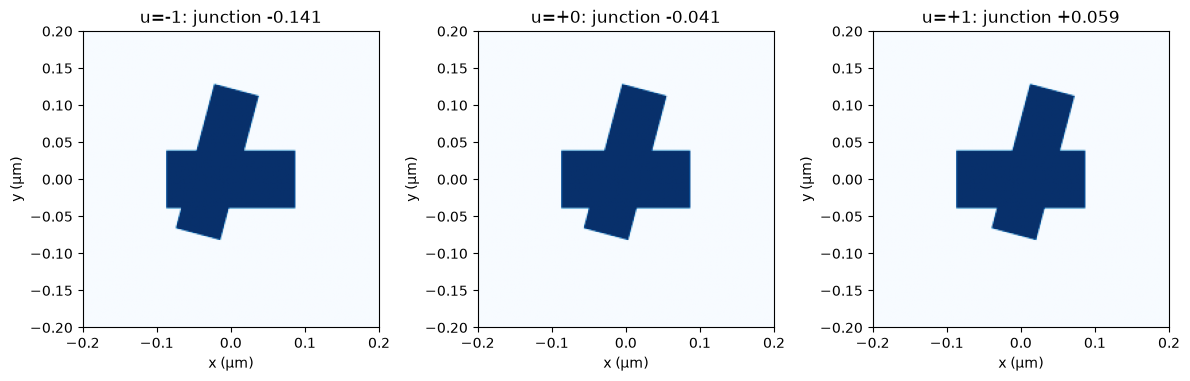

S (bottom x/y, top x/y):
 [[-0.1867+0.1945j -0.3252-0.2439j  0.2371-0.6015j  0.0407-0.1131j]
 [-0.3252-0.2439j -0.2203+0.1982j  0.0349-0.1529j  0.2765-0.55j  ]
 [ 0.2371-0.6015j  0.0349-0.1529j -0.3934+0.003j  -0.0181-0.3216j]
 [ 0.0407-0.1131j  0.2765-0.55j   -0.0181-0.3216j -0.4132-0.1013j]]
k̂ = [1.0147+0.0193j 0.0581+0.1359j 0.1458-0.1883j] | γ+ = 2.9591-0.4270j, γ- = 3.3241+0.4270j
‖T-Tᵀ‖/‖T‖ = 6.230e-02 | reciprocity ‖S-Sᵀ‖ = 2.6e-12
x from substrate: T=0.432 R=0.238 absorbed=0.330
y from substrate: T=0.404 R=0.253 absorbed=0.343
Layout: {'svg': 'results/complex_pb_v4/complex_pb_mask.svg', 'gds': 'results/complex_pb_v4/complex_pb_mask.gds'}


In [5]:
if best_raw is not None:
    pbest = design_from_raw(torch.tensor(best_raw, device=DEVICE, dtype=torch.float64))
    geom = {k: float(v) for k, v in pbest.items()}
    area, connected = check_connected(geom)
    print('Geometry:', {k: round(v, 4) for k, v in geom.items()}, '| connected:', connected)
    fig, axs = plt.subplots(1, 3, figsize=(12, 4))
    for ax, u in zip(axs, (-1., 0., 1.)):
        q = {k: torch.tensor(float(v), dtype=torch.float64) for k, v in vary(geom, MOD, u).items()}
        with torch.no_grad(): m = twofin_mask(q, PHYS, 220, mode='aa').numpy()
        half = PHYS.period/2
        ax.imshow(m.T, origin='lower', extent=(-half, half, -half, half), cmap='Blues', vmin=0, vmax=1)
        ax.set(title=f'u={u:+.0f}: junction {q["junction_frac"].item():+.3f}', xlabel='x (µm)', ylabel='y (µm)')
    plt.tight_layout(); plt.show()
    with torch.no_grad(): S = solve_torch(pbest, PHYS, ACCEPT).cpu().numpy()
    T = S[2:4, :2]; gp, gm = theta_loop_phase(T)
    print('S (bottom x/y, top x/y):\n', np.array2string(S, precision=4))
    print(f'k̂ = {np.round(pauli_khat(T), 4)} | γ+ = {gp:.4f}, γ- = {gm:.4f}')
    print(f'‖T-Tᵀ‖/‖T‖ = {transpose_asymmetry(T):.3e} | reciprocity ‖S-Sᵀ‖ = {np.linalg.norm(S-S.T):.1e}')
    for j, pol in enumerate('xy'):
        tr = np.sum(abs(S[2:4, j])**2); rf = np.sum(abs(S[:2, j])**2)
        print(f'{pol} from substrate: T={tr:.3f} R={rf:.3f} absorbed={1-tr-rf:.3f}')
    print('Layout:', export_layout(geom, PHYS, OUT/'complex_pb_mask'))

## Convergence: Fourier order and raster

In [6]:
def ky_at(q, opts, theta=0.):
    with torch.no_grad(): S = solve_torch(q, PHYS, opts, theta_deg=theta).cpu().numpy()
    return pauli_khat(S[2:4, :2])[1], numpy_metrics(S)
conv = []
if best_raw is not None and RUN_VERIFY:
    for o in VERIFY_ORDERS:
        opts = RCWA(order=o, raster=256, device=DEVICE, precision='complex128')
        ks = [ky_at(vary(pbest, MOD, u), opts)[0] for u in (-1., 0., 1.)]
        conv.append(dict(order=o, ky=[complex(k) for k in ks]))
        print(f'order {o:2}: k_y(u=-1,0,1) = ' + ', '.join(f'{k.real:+.4f}{k.imag:+.4f}i' for k in ks), flush=True)
    for r in (192, 256, 384):
        opts = RCWA(order=12, raster=r, device=DEVICE, precision='complex128')
        ks = [ky_at(vary(pbest, MOD, u), opts)[0] for u in (-1., 0., 1.)]
        print(f'raster {r}: k_y(u=-1,0,1) = ' + ', '.join(f'{k.real:+.4f}{k.imag:+.4f}i' for k in ks), flush=True)

order  8: k_y(u=-1,0,1) = +0.0465+0.0551i, +0.0962+0.1317i, +0.1528-0.5782i


order 10: k_y(u=-1,0,1) = +0.0360+0.0509i, +0.0606+0.1321i, +0.3348-0.5155i


order 12: k_y(u=-1,0,1) = +0.0360+0.0510i, +0.0581+0.1359i, +0.2906-0.4645i


order 14: k_y(u=-1,0,1) = +0.0361+0.0500i, +0.0660+0.1322i, +0.2325-0.5510i


order 16: k_y(u=-1,0,1) = +0.0357+0.0508i, +0.0677+0.1344i, +0.2484-0.5718i


raster 192: k_y(u=-1,0,1) = +0.0331+0.0505i, +0.0450+0.1403i, +0.2820-0.3713i


raster 256: k_y(u=-1,0,1) = +0.0360+0.0510i, +0.0581+0.1359i, +0.2906-0.4645i


raster 384: k_y(u=-1,0,1) = +0.0315+0.0501i, +0.0507+0.1360i, +0.3224-0.4411i


## Dense modulation sweep: Im γ (amplitude geometry) vs Re γ (path-dependent PB phase)

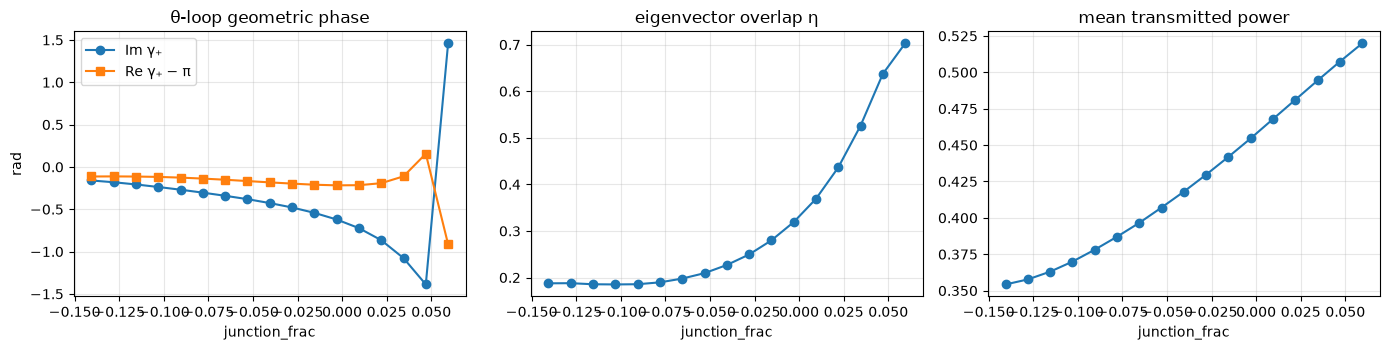

Im γ span 2.848 rad | Re γ span 1.068 rad | P min 0.35


In [7]:
sweep = []
if best_raw is not None and RUN_VERIFY:
    for u in np.linspace(-1, 1, 17):
        k, m = ky_at(vary(pbest, MOD, float(u)), ACCEPT)
        sweep.append(dict(u=float(u), junction=geom['junction_frac']+u*MOD.amplitude, im_gamma=float(-np.pi*k.imag),
                          re_gamma=float(np.pi*(1-k.real)), eta=m['eta'], gap=m['gap'], power=m['power']))
    fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
    x = [s['junction'] for s in sweep]
    axs[0].plot(x, [s['im_gamma'] for s in sweep], 'o-', label='Im γ₊'); axs[0].plot(x, [s['re_gamma']-np.pi for s in sweep], 's-', label='Re γ₊ − π')
    axs[0].set(xlabel='junction_frac', ylabel='rad', title='θ-loop geometric phase'); axs[0].legend()
    axs[1].plot(x, [s['eta'] for s in sweep], 'o-'); axs[1].set(xlabel='junction_frac', title='eigenvector overlap η')
    axs[2].plot(x, [s['power'] for s in sweep], 'o-'); axs[2].set(xlabel='junction_frac', title='mean transmitted power')
    for a in axs: a.grid(alpha=.3)
    plt.tight_layout(); plt.show()
    im = [s['im_gamma'] for s in sweep]; re = [s['re_gamma'] for s in sweep]
    print(f'Im γ span {max(im)-min(im):.3f} rad | Re γ span {max(re)-min(re):.3f} rad | P min {min(s["power"] for s in sweep):.2f}')

## Locality: rotation inside the lattice, and period
For a local meta-atom $\hat k_y$ is exactly rotation-invariant, so any θ dependence comes from the lattice (evanescent and guided
coupling between neighbors). A period sweep at fixed geometry is a second check: lattice resonances move with the period, local
responses barely do.

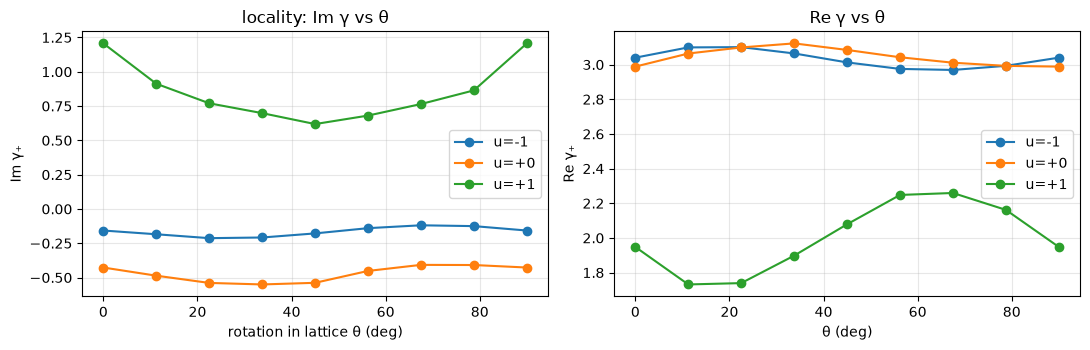

u=-1: Im γ over θ: mean -0.165, spread 0.094 rad
u=+0: Im γ over θ: mean -0.470, spread 0.143 rad
u=+1: Im γ over θ: mean +0.858, spread 0.588 rad
Period sweep (geometry fixed), k_y at u=0:


  period 360 nm: Im γ = +0.156, Re γ = 3.212, P = 0.33


  period 380 nm: Im γ = +0.175, Re γ = 3.304, P = 0.35


  period 400 nm: Im γ = -0.427, Re γ = 2.988, P = 0.42


  period 420 nm: Im γ = -0.042, Re γ = 2.889, P = 0.37


  period 440 nm: Im γ = -0.185, Re γ = 2.627, P = 0.37


In [8]:
loc = {}
if best_raw is not None and RUN_VERIFY:
    thetas = np.arange(0, 90.1, 11.25)
    for u in (-1., 0., 1.):
        loc[u] = [ky_at(vary(pbest, MOD, u), REFINE, float(t))[0] for t in thetas]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    for u, ks in loc.items():
        ax[0].plot(thetas, [-np.pi*k.imag for k in ks], 'o-', label=f'u={u:+.0f}')
        ax[1].plot(thetas, [np.pi*(1-k.real) for k in ks], 'o-', label=f'u={u:+.0f}')
    ax[0].set(xlabel='rotation in lattice θ (deg)', ylabel='Im γ₊', title='locality: Im γ vs θ'); ax[1].set(xlabel='θ (deg)', ylabel='Re γ₊', title='Re γ vs θ')
    for a in ax: a.legend(); a.grid(alpha=.3)
    plt.tight_layout(); plt.show()
    for u, ks in loc.items():
        im = np.array([-np.pi*k.imag for k in ks]); print(f'u={u:+.0f}: Im γ over θ: mean {im.mean():+.3f}, spread {im.max()-im.min():.3f} rad')
    print('Period sweep (geometry fixed), k_y at u=0:')
    for per in (0.36, 0.38, 0.40, 0.42, 0.44):
        with torch.no_grad(): S = solve_torch(pbest, replace(PHYS, period=per), REFINE).cpu().numpy()
        k = pauli_khat(S[2:4, :2])[1]; print(f'  period {per*1000:.0f} nm: Im γ = {-np.pi*k.imag:+.3f}, Re γ = {np.pi*(1-k.real):.3f}, P = {numpy_metrics(S)["power"]:.2f}')

## Full-RCWA θ-loop Wilson check
Discrete biorthogonal Wilson loops over actual lattice RCWA solutions, θ: 0 → 180°, compared with the one-solve formula. Coarse loops
carry $O(N^{-2})$ discretization error and must be refined. The 24-point loop in v2/v3 was dominated by that error.

In [9]:
wilson = {}
if best_raw is not None and RUN_VERIFY:
    for u in (-1., 0., 1.):
        for n in (32, 64):
            Ts = []
            for t in np.linspace(0, 180, n, endpoint=False):
                with torch.no_grad(): Ts.append(solve_torch(vary(pbest, MOD, u), PHYS, REFINE, theta_deg=float(t)).cpu().numpy()[2:4, :2])
            g = virtual_wilson(Ts)['gamma']; wilson[(u, n)] = g
            gp, gm = theta_loop_phase(Ts[0])
            print(f'u={u:+.0f} N={n}: Wilson γ = {np.round(g, 3)} | formula γ± = {gp:.3f}, {gm:.3f}', flush=True)

u=-1 N=32: Wilson γ = [-3.032+0.009j  3.029-0.32j ] | formula γ± = 3.040-0.157j, 3.243+0.157j


u=-1 N=64: Wilson γ = [-3.031+0.086j  3.03 -0.242j] | formula γ± = 3.040-0.157j, 3.243+0.157j


u=+0 N=32: Wilson γ = [-3.056+0.319j  3.057-0.636j] | formula γ± = 2.988-0.427j, 3.295+0.427j


u=+0 N=64: Wilson γ = [-3.058+0.396j  3.058-0.555j] | formula γ± = 2.988-0.427j, 3.295+0.427j


u=+1 N=32: Wilson γ = [ 2.036+0.698j -1.987-0.971j] | formula γ± = 1.948+1.207j, 4.335-1.207j


u=+1 N=64: Wilson γ = [ 2.027+0.758j -2.007-0.888j] | formula γ± = 1.948+1.207j, 4.335-1.207j


## How the parameters act: sensitivities at u = 0, and fabrication robustness

In [10]:
sens = {}
if best_raw is not None and RUN_VERIFY:
    steps = {'length1': .006, 'width1': .004, 'length2': .006, 'width2': .004, 'bend_deg': 2., 'junction_frac': .02}
    for key, st in steps.items():
        ks = []
        for s in (-1, 1):
            q = dict(pbest); q[key] = pbest[key] + s*st; ks.append(ky_at(q, REFINE)[0])
        d = (ks[1]-ks[0])/(2*st); sens[key] = d
        print(f'{key:13} dImγ/dp = {-np.pi*d.imag:+9.3f}   dReγ/dp = {-np.pi*d.real:+9.3f}   (per µm, per degree, or per unit fraction)')
    rng = np.random.default_rng(SEED + 9); spans = []
    sd = dict(length1=.004, width1=.003, length2=.004, width2=.003, bend_deg=1.5, junction_frac=.01)
    for trial in range(8):
        q = {k: v + float(rng.normal(scale=sd[k])) for k, v in pbest.items()}
        im = [-np.pi*ky_at(vary(q, MOD, u), REFINE)[0].imag for u in (-1., 0., 1.)]
        spans.append(max(im)-min(im))
    print('Im γ span under fabrication perturbations:', np.round(spans, 3))

length1       dImγ/dp =   -39.267   dReγ/dp =   -26.655   (per µm, per degree, or per unit fraction)


width1        dImγ/dp =   -74.398   dReγ/dp =   -24.599   (per µm, per degree, or per unit fraction)


length2       dImγ/dp =    +5.421   dReγ/dp =   +13.521   (per µm, per degree, or per unit fraction)


width2        dImγ/dp =   -52.392   dReγ/dp =   -32.678   (per µm, per degree, or per unit fraction)


bend_deg      dImγ/dp =    -0.012   dReγ/dp =    -0.013   (per µm, per degree, or per unit fraction)


junction_frac dImγ/dp =    -4.283   dReγ/dp =    -0.667   (per µm, per degree, or per unit fraction)


Im γ span under fabrication perturbations: [0.014 0.131 0.249 0.254 1.192 0.096 0.54  0.028]


## Export

In [11]:
if best_raw is not None:
    np.savez_compressed(OUT/'complex_pb_final.npz', raw=best_raw, geometry=json.dumps(geom), physics=json.dumps(asdict(PHYS)),
        modulation=json.dumps(asdict(MOD)), sweep=json.dumps(sweep), convergence=json.dumps(conv, default=str),
        locality=json.dumps({str(u): [str(complex(k)) for k in ks] for u, ks in loc.items()}),
        wilson=json.dumps({f'{u}_{n}': [str(x) for x in g] for (u, n), g in wilson.items()}),
        sensitivity=json.dumps({k: str(complex(v)) for k, v in sens.items()}))
    print('Saved under', OUT.resolve())

Saved under /home/coopah/Desktop/python-projects/Metasurface-Design/metaatomsim-torcwa/05_twofin_eta_control/results/complex_pb_v4
